# Разведочный Sanity Check (черновой блокнот перед пайплайном)

Перед тем как писать большой пайплайн и гонять трансформеры на миллионе цифр, хочу быстро пощупать данные руками: проверить частоты первых $100\,000$ знаков $\pi$, убедиться на перемешанном массиве, что базовые проверки не врут, прикинуть скорость генерации и посмотреть, как ведут себя подстроки в дроби `1/97`.

In [1]:
import time
from pathlib import Path

import mpmath as mp
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from scipy import stats

ROOT_DIR = Path.cwd().resolve()
if not (ROOT_DIR / "src").exists() and (ROOT_DIR.parent / "src").exists():
    ROOT_DIR = ROOT_DIR.parent

SEED = 42
N_DIGITS = 100_000
rng = np.random.default_rng(SEED)

cache_path = ROOT_DIR / "data" / "true_pi_digits.npy"
t0 = time.perf_counter()
if cache_path.exists():
    pi_digits = np.load(cache_path)[:N_DIGITS].copy()
    source = f"кэш {cache_path.name}"
else:
    with mp.workdps(N_DIGITS + 32):
        s = mp.nstr(mp.pi - 3, N_DIGITS + 10, strip_zeros=False).split(".", 1)[1][:N_DIGITS]
    pi_digits = (np.frombuffer(s.encode("ascii"), dtype=np.uint8) - ord("0")).copy()
    source = "генерация mpmath"

print(f"Загружено {len(pi_digits):,} цифр pi ({source}) за {time.perf_counter() - t0:.4f} с")

Загружено 100,000 цифр pi (кэш true_pi_digits.npy) за 0.0007 с


In [2]:
print('shape & dtype:', len(pi_digits), pi_digits.dtype)
print('pi[:60]:', ''.join(map(str, pi_digits[:60].tolist())))

shape & dtype: 100000 uint8
pi[:60]: 141592653589793238462643383279502884197169399375105820974944


chi2 = 4.0930, p = 0.9052 | макс. отклонение: цифра 1 (+0.137 п.п.)


,digit,count,share_pct,diff_pp
0,0,9999,9.999,-0.001
1,1,10137,10.137,0.137
2,2,9908,9.908,-0.092
3,3,10025,10.025,0.025
4,4,9971,9.971,-0.029
5,5,10026,10.026,0.026
6,6,10029,10.029,0.029
7,7,10025,10.025,0.025
8,8,9978,9.978,-0.022
9,9,9902,9.902,-0.098


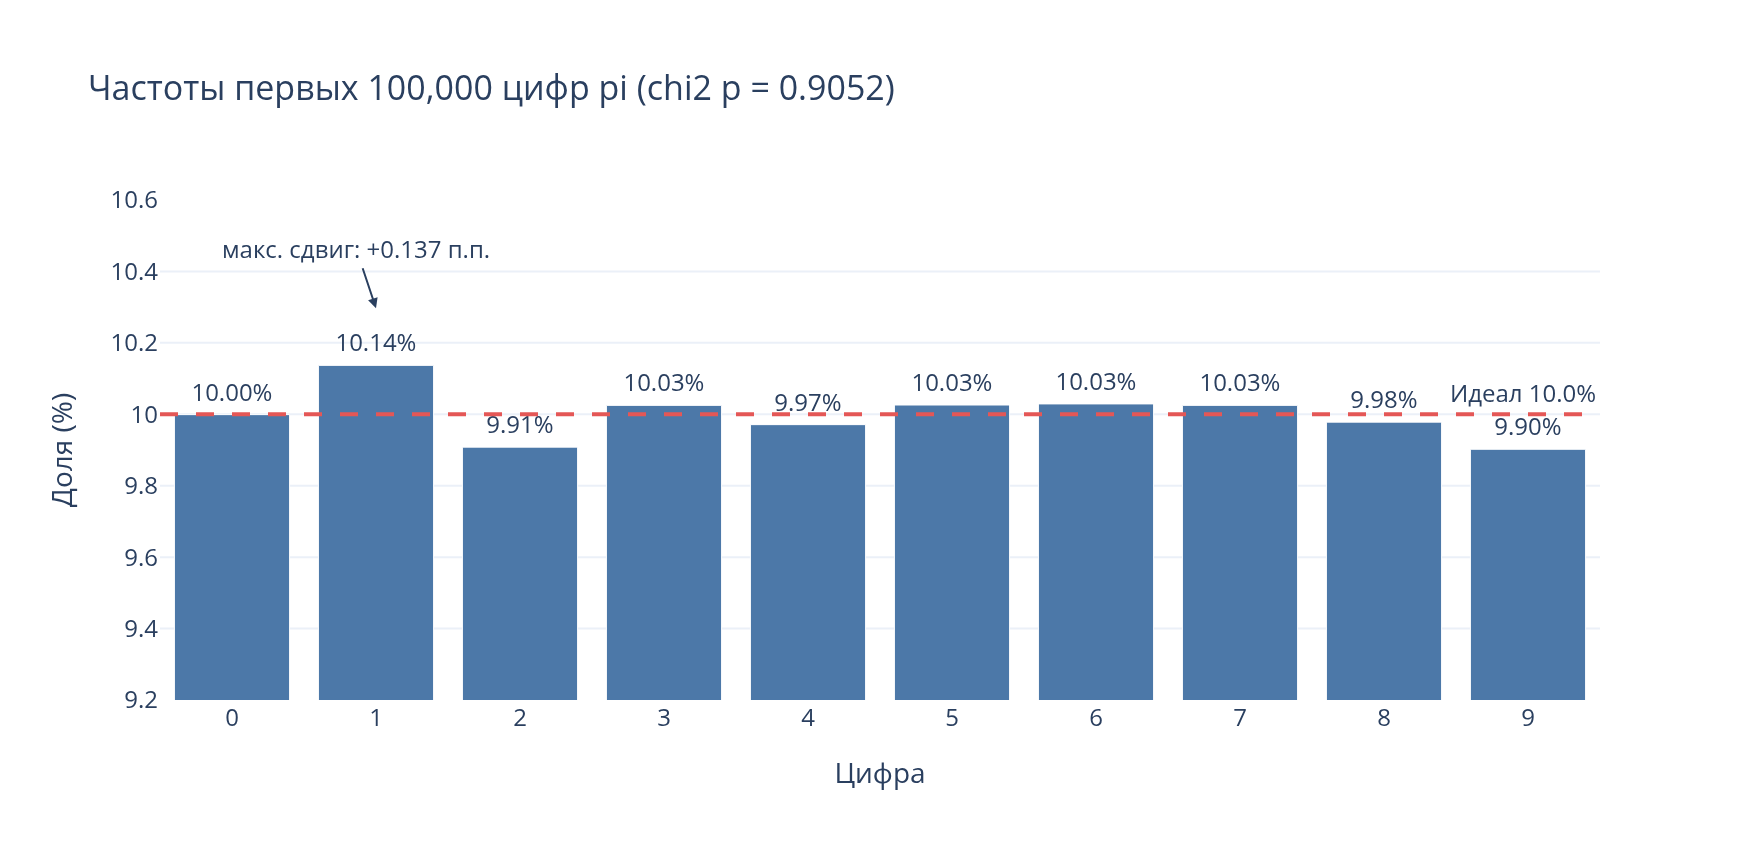

In [3]:
from IPython.display import Image, display

counts = np.bincount(pi_digits, minlength=10)
shares = 100.0 * counts / len(pi_digits)
chi2_stat, chi2_p = stats.chisquare(counts, f_exp=np.full(10, len(pi_digits) / 10.0))

max_dev_digit = int(np.argmax(np.abs(shares - 10.0)))
max_dev_val = shares[max_dev_digit] - 10.0
print(f"chi2 = {chi2_stat:.4f}, p = {chi2_p:.4f} | макс. отклонение: цифра {max_dev_digit} ({max_dev_val:+.3f} п.п.)")

freq_df = pd.DataFrame({
    "digit": np.arange(10),
    "count": counts,
    "share_pct": np.round(shares, 3),
    "diff_pp": np.round(shares - 10.0, 3),
})
display(freq_df)

fig_freq = go.Figure([
    go.Bar(x=freq_df["digit"], y=freq_df["share_pct"], marker_color="#4C78A8", text=freq_df["share_pct"].map(lambda v: f"{v:.2f}%"), textposition="outside")
])
fig_freq.add_hline(y=10.0, line_dash="dash", line_color="#E45756", annotation_text="Идеал 10.0%")
fig_freq.add_annotation(
    x=max_dev_digit, y=shares[max_dev_digit] + 0.16,
    text=f"макс. сдвиг: {max_dev_val:+.3f} п.п.", showarrow=True, arrowhead=2,
)
fig_freq.update_layout(
    title=f"Частоты первых {N_DIGITS:,} цифр pi (chi2 p = {chi2_p:.4f})",
    xaxis=dict(title="Цифра", dtick=1),
    yaxis=dict(title="Доля (%)", range=[9.2, 10.6]),
    template="plotly_white", width=880, height=430,
)
display(Image(fig_freq.to_image(format="png", width=880, height=430, scale=2)))

In [4]:
from src.baselines import compute_empirical_transition_matrix
from src.dataset import SequenceWindowDataset, split_sequence_chronologically, verify_zero_leakage

pi_shuffled = rng.permutation(pi_digits)
split_pi = split_sequence_chronologically(pi_digits, mask=None, train_ratio=0.8, val_ratio=0.1, test_ratio=0.1)
tr_ds = SequenceWindowDataset(split_pi.train_digits, window_size=64, global_offset=split_pi.train_range[0])
va_ds = SequenceWindowDataset(split_pi.val_digits, window_size=64, global_offset=split_pi.val_range[0])
te_ds = SequenceWindowDataset(split_pi.test_digits, window_size=64, global_offset=split_pi.test_range[0])
leak_check = verify_zero_leakage(split_pi, window_size=64, train_ds=tr_ds, val_ds=va_ds, test_ds=te_ds)

t_pi = compute_empirical_transition_matrix(pi_digits, radix=10)
t_shuf = compute_empirical_transition_matrix(pi_shuffled, radix=10)

print("Zero leakage check:", leak_check["zero_overlap_verified"], "| train/val/test windows:", leak_check["train_windows"], leak_check["val_windows"], leak_check["test_windows"])
print(f"Max |P(x[t+1]|x[t]) - 0.10| -> true_pi: {np.max(np.abs(t_pi - 0.1)):.5f} | shuffled_pi: {np.max(np.abs(t_shuf - 0.1)):.5f}")
print(f"Mean |T_pi - T_shuffled|: {np.mean(np.abs(t_pi - t_shuf)):.5f}")
pd.DataFrame(np.round(t_pi, 4), index=[f"from_{i}" for i in range(10)], columns=[f"to_{j}" for j in range(10)])

Zero leakage check: True | train/val/test windows: 79936 9936 9936
Max |P(x[t+1]|x[t]) - 0.10| -> true_pi: 0.00973 | shuffled_pi: 0.00974
Mean |T_pi - T_shuffled|: 0.00319


,to_0,to_1,to_2,to_3,to_4,to_5,to_6,to_7,to_8,to_9
from_0,0.0998,0.1027,0.0962,0.0993,0.0968,0.1007,0.1009,0.1017,0.1001,0.1017
from_1,0.1028,0.1020,0.0979,0.0996,0.1016,0.0958,0.0969,0.0994,0.1030,0.1010
from_2,0.0983,0.1074,0.0980,0.0975,0.0952,0.1012,0.1058,0.1026,0.0964,0.0976
from_3,0.0977,0.0972,0.0992,0.1005,0.1038,0.1072,0.0963,0.1006,0.0980,0.0996
from_4,0.1023,0.1004,0.0990,0.1017,0.0974,0.0965,0.1036,0.1011,0.0978,0.1003
from_5,0.0963,0.0963,0.1026,0.1028,0.1016,0.1012,0.1014,0.1001,0.1005,0.0968
from_6,0.1051,0.1009,0.1045,0.0994,0.1017,0.0995,0.0950,0.0969,0.0946,0.1022
from_7,0.0946,0.1043,0.0979,0.1028,0.0943,0.0959,0.1097,0.1009,0.1037,0.0959
from_8,0.1013,0.0998,0.0994,0.0948,0.1003,0.1022,0.0972,0.1046,0.1029,0.0973
from_9,0.1017,0.1026,0.0961,0.1039,0.1043,0.1024,0.0961,0.0943,0.1007,0.0978


In [5]:
from src.data_generator import generate_rational_digits

bench_rows = []
for label, fn in [("mpmath: pi", lambda: mp.pi - 3), ("mpmath: sqrt(2)", lambda: mp.sqrt(2) - 1)]:
    t0 = time.perf_counter()
    with mp.workdps(N_DIGITS + 32):
        s = mp.nstr(fn(), N_DIGITS + 10, strip_zeros=False).split(".", 1)[1][:N_DIGITS]
    arr = np.frombuffer(s.encode("ascii"), dtype=np.uint8) - ord("0")
    dt = time.perf_counter() - t0
    bench_rows.append({"method": label, "n_digits": len(arr), "time_sec": round(dt, 4)})

t0 = time.perf_counter()
rat_arr = generate_rational_digits(1, 999983, N_DIGITS, radix=10)
dt_rat = time.perf_counter() - t0
bench_rows.append({"method": "деление столбиком: 1/999983", "n_digits": len(rat_arr), "time_sec": round(dt_rat, 4)})

pd.DataFrame(bench_rows)

,method,n_digits,time_sec
0,mpmath: pi,100000,0.1834
1,mpmath: sqrt(2),100000,0.0516
2,деление столбиком: 1/999983,100000,0.0233


,context_k,distinct_kgrams,unique_positions,unique_share_pct
0,1,10,0,0.0
1,2,96,96,100.0
2,3,96,96,100.0
3,4,96,96,100.0
4,5,96,96,100.0
5,6,96,96,100.0
6,7,96,96,100.0
7,8,96,96,100.0


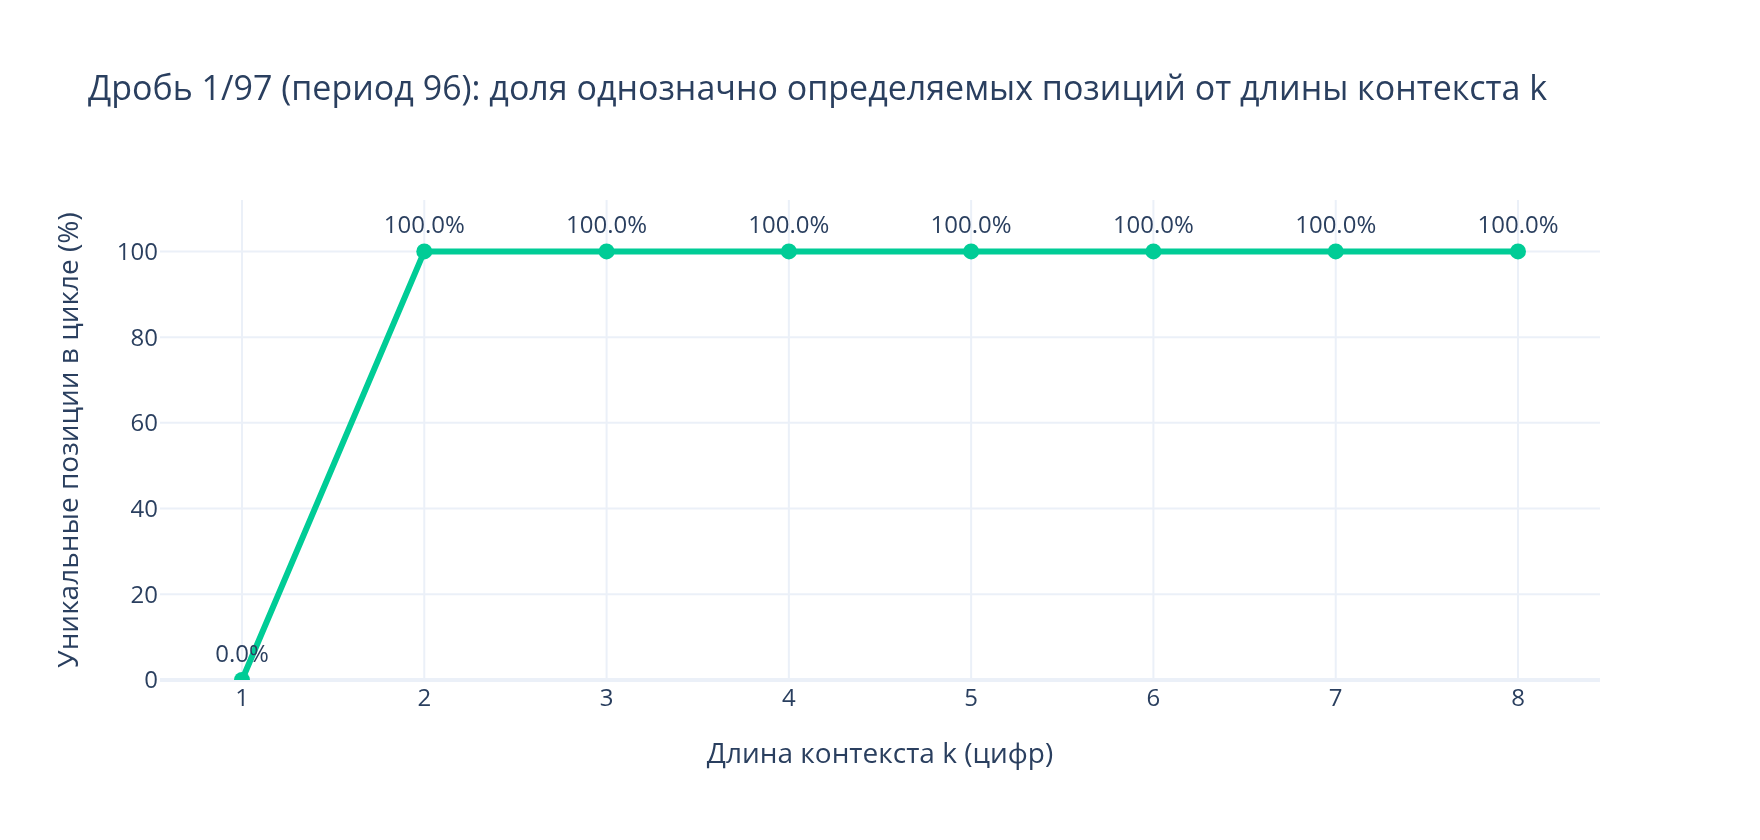

In [6]:
# Период дроби 1/97 равен 96; смотрим, при какой длине подстроки k все позиции в цикле становятся уникальными
period_97 = generate_rational_digits(1, 97, 96, radix=10)
assert np.array_equal(period_97, generate_rational_digits(1, 97, 192, radix=10)[96:])

k_rows = []
doubled = np.concatenate([period_97, period_97])
for k in range(1, 9):
    substrings = [tuple(doubled[i : i + k].tolist()) for i in range(96)]
    counts_sub = pd.Series(substrings).value_counts()
    unique_positions = int(counts_sub[counts_sub == 1].sum())
    k_rows.append({
        "context_k": k,
        "distinct_kgrams": int(len(counts_sub)),
        "unique_positions": unique_positions,
        "unique_share_pct": round(100.0 * unique_positions / 96.0, 2),
    })

k_df = pd.DataFrame(k_rows)
display(k_df)

fig_k = go.Figure([
    go.Scatter(
        x=k_df["context_k"], y=k_df["unique_share_pct"],
        mode="lines+markers+text",
        text=k_df["unique_share_pct"].map(lambda v: f"{v:.1f}%"),
        textposition="top center",
        line=dict(color="#00CC96", width=3), marker=dict(size=8),
    )
])
fig_k.update_layout(
    title="Дробь 1/97 (период 96): доля однозначно определяемых позиций от длины контекста k",
    xaxis=dict(title="Длина контекста k (цифр)", dtick=1),
    yaxis=dict(title="Уникальные позиции в цикле (%)", range=[0, 112]),
    template="plotly_white", width=880, height=420,
)
display(Image(fig_k.to_image(format="png", width=880, height=420, scale=2)))

## Итоги разведки

Первые $100\,000$ цифр $\pi$ проходят тест $\chi^2$ с запасом, а матрица переходов `10x10` практически не отличается от случайно перемешанного массива — сплит без утечек (`verify_zero_leakage`) работает чисто. Замер на CPU показал, что блочное целочисленное деление для `1/999983` работает в разы быстрее длинной арифметики `mpmath`. Наконец, на периоде дроби `1/97` проявилось удивительное свойство: при $k = 1$ уникальных позиций `0%`, а уже при $k = 2$ **все 96 из 96 двузначных подстрок внутри цикла уникальны (`100.0%`)**, поэтому на `1/97` не стоит ждать фазового перехода при $L = 64 \to 128$. Дальше переношу все эксперименты в полноценные скрипты `src/` и `experiments/`.